# Фильтр Калмана

Рассказ про фильтр Колмогорова-Винера

Объяснение фильтра Калмана в картинках

https://habr.com/ru/articles/59424s/07

## Содержание

- Введение в фильтр Калмана.
- Компоненты модели и допущения.
- Алгоритм фильтра Калмана.
- Применение к статическим и динамическим одномерным данным.
- Применение к многомерным данным.

---

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import cv2
np.random.seed(0)

## Что такое фильтр Калмана?

- Фильтр Калмана (ФК) — это алгоритм, использующий серию измерений, наблюдаемых во времени, содержащих статистический шум и другие неточности.
- Он позволяет получить оценки неизвестных переменных, которые, как правило, более точны, чем оценки, основанные только на измерениях.
- Разработан Рудольфом Э. Кальманом в конце 1950-х годов.
- Приложения:
  - отслеживание объектов (проект «Аполлон», GPS, беспилотные автомобили).
  - обработка изображений.
  - экономическое и финансовое моделирование.

### Теоретические основы

- Динамические системы — это системы, которые изменяются со времене.

- Они описываются набором уравнений, которые предсказывают будущее состояние системы на основе её текущего состояия.

- Фильтр Калмана предполагает, что система является *линейной* динамической системой с *гауссовым* шумом.
- Гауссовы распределения используются из-за их хороших свойств при работе со средними значениями и дисперсиями.

### Каковы составляющие?

**Состояние**
- Истинное значение переменных, которые мы хотим оцениь.

- Вектор состояния представляет всю информацию, необходимую для описания текущего состояния системы.

**Модель наблюдений**
- Связывает текущее состояние с измерениями или наблюдениями.

**Зашумленные измерения**
- Шум процесса и шум измерений (предполагается, что они имеют гауссовское распределение) отражают неопределенность в наших моделях и измерениях.

Пример:
- Автомобиль движется с постоянной скоростью.
- Модель: Положение автомобиля = скорость $\times$ время $+$ системный шум.
- Измерения: положение и скорость (которые также содержат шум).

### Роль шума

Компромисс между влиянием модели и измерений определяется шумом.

- Если модель имеет относительно большие ошибки, большее значение придается последним измерениям при вычислении текущей оценки.

- Если измерения имеют большие ошибки, большее значение придается модели при построении текущей оценки.

- Следовательно, необходимо оценивать не только ваше состояние, но и ошибки (ковариацию) как для модели, так и для измерений.

- Их также необходимо обновлять на каждом временном шаге.

### Стратегия обновления

КФ — рекурсивный алгоритм:

- Использует информацию с предыдущего шага по времени для обновления оценок.

- Не хранит в памяти все полученные к этому моменту данные.

- Имеет структуру предиктора-корректора:

- Делает прогноз на основе модели.

- Обновляет прогноз с помощью измерений.

- Повторить.

### Основные предположения

Подход с использованием фильтра Калмана основан на трех основных предположениях:

1. Систему можно описать или аппроксимировать линейной моделью.

2. Весь шум (как от системы, так и от измерений) является белым, т.е. значения не коррелированы.

3. Весь шум является гауссовым.

#### Предположение 1: линейность

Каждая переменная в текущий момент времени является линейной функцией переменных за предыдущие моменты времени.

- Многие системы можно аппроксимировать таким образом.

- Линейные системы легко анализировать.

- Нелинейные системы часто можно аппроксимировать линейными моделями вокруг текущей оценки (расширенный фильтр Калмана).

#### Предположение 2: Белый шум

Значения шума не коррелированы во времени.

- Если известен уровень шума в момент времени $t$, это не поможет предсказать уровень шума в будущие моменты времени $t+\tau$.

- Белый шум является разумным приближением к реальному шуму.

- Это предположение делает математические вычисления выполнимыми.

<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">&#9998 Note</b>
</p>

Белый шум представляет собой смесь всех различных частот одинаковой интенсивности, смешанных вместе.

Это похоже на то, как белый свет содержит все цвета радуги вместе взятые.


#### Предположение 3: Гауссовский шум

В любой момент времени плотность вероятности шума имеет гауссовское распределение.

- Шум системы и измерений часто представляет собой комбинацию множества малых источников шума.
- Эффект комбинации приблизительно гауссовский.

- Если известны только среднее значение и дисперсия (типичный случай в инженерных системах), гауссовское распределение является хорошим выбором, поскольку эти две величины полностью определяют гауссовское распределение.

- Гауссовское распределение обладает хорошими свойствами и легко поддается математическому анализу.

---

## 1.3. Технические подробности

### Объединение двух источников

Предположим, автомобиль находится в определенном начальном положении $x_0=0$ и имеет начальную скорость $\dot{x}_0=60 км/ч$.

Если скорость постоянна, то имеем:

$$x_{t} = 1\cdot x_{t-1} + \delta t \cdot \dot{x}_{t-1}$$
$$\dot{x}_{t} = 0 \cdot x_{t-1} + 1 \cdot \dot{x}_{t-1}$$


В матричной форме:

$$ \boldsymbol{x}_{t} =
\begin{bmatrix}
x_{t} \\
\dot{x}_{t}
\end{bmatrix}
=
\begin{bmatrix}
1 & \delta t \\
0 & 1
\end{bmatrix}
\begin{bmatrix}
x_{t-1} \\
\dot{x}_{t-1}
\end{bmatrix} = \mathbf{A} \boldsymbol{x}_{t-1}
$$

<img src="media/system.png" style="width: 50%; display: block; margin: auto;">

- Текущее положение и скорость будут изменяться в соответствии с простой динамической системой.

$$\boldsymbol{x}_{t} = \mathbf{A} \boldsymbol{x}_{t-1} + \boldsymbol{w}_{t-1}$$

- где $\boldsymbol{w}_t \sim \mathcal{N}(0,\mathbf{Q})$ представляет собой возмущения в лежащих в основе динамических системах (например, ямы на дороге).
- $\boldsymbol{x}_{t} \in \mathbb{R}^{N}$ отражает состояние системы.
- $\mathbf{Q} \in \mathbb{R}^{N \times N}$ — это *ковариация шума процесса*, где $N$ обозначает количество переменных состояния (в нашем случае 2: ​​положение и скорость).

Где окажется машина через 1 минуту?

Если мы будем полагаться только на нашу простую систему $\boldsymbol{x}_{t+1} = \mathbf{A} \boldsymbol{x}_{t}$, даже не принимая во внимание шум, машина продолжит движение со скоростью $60 км/ч$ и окажется на расстоянии $1 км$.

<img src="media/model_pred.png" style="width: 50%; display: block; margin: auto;">

Допустим, в нашей машине есть GPS.

- Как и любой прибор, наш GPS подвержен ошибкам и выдает измерения с погрешностями.

- Кроме того, наш GPS может измерять только местоположение, но не скорость.

- На основе данных GPS, через 1 минуту мы окажемся на расстоянии 0,8 км от начальной точки.

<img src="media/gps.png" style="width: 50%" align="center">

- Пусть измерение нашего GPS будет следующим:

$$\boldsymbol{z}_t = \mathbf{H} \boldsymbol{x}_t + \boldsymbol{v}_t$$

- где $\boldsymbol{v}_t \sim \mathcal{N}(0,\mathbf{R})$ отражает неопределенность в измерениях.
- $\boldsymbol{z}_{t} \in \mathbb{R}^{M}$ — это вектор измерений.
- В нашем случае, поскольку GPS измеряет только местоположение, у нас есть $\mathbf{H} = \begin{bmatrix} 1 & 0 \end{bmatrix}$ and $\mathbf{R} = \begin{bmatrix} r_{xx} \end{bmatrix}$.
- В общем случае, $\mathbf{H} \in \mathbb{R}^{M\times N}$ — это матрица, отображающая $N$ переменных состояния в $M$ измерений, а $\mathbf{R} \in \mathbb{R}^{M\times M}$ — ковариация шума измерений.

Таким образом, у нас есть два разных источника информации:
- линейное стохастическое разностное уравнение, представляющее наши неточные знания о дискретном управляемом процессе;
- источник измерений, которыq является зашумленным.

<img src="media/inputs.png" style="width: 25%; display: block; margin: auto;">

Как нам объединить их, чтобы получить максимально точную оценку переменных нашей системы?

### Алгоритм фильтра Калмана

Фильтр Калмана — это итеративная процедура, состоящая из двух шагов:

- **Прогнозирование** (обновление по времени)

- **Коррекция** (обновление по измерениям)

Эти два шага используются для обновления двух величин:
- **оценки состояния**.

- Неопределенности нашей оценки состояния, называемой **оценкой ковариации**.

Прежде чем рассматривать итеративную процедуру, давайте введем эту вторую величину.

**Оценка ковариации**

В оценке состояния нашей системы присутствуют два источника ошибок.

- *Априорная* ошибка оценки $\boldsymbol{e}^{-}_t = \boldsymbol{x}_t - \hat{\boldsymbol{x}}^{-}_t$.

- *Апостериорная* ошибка оценки $\boldsymbol{e}_t = \boldsymbol{x}_t - \hat{\boldsymbol{x}}_t$.

Где:
- $\hat{\boldsymbol{x}}^{-}_t$ — оценка состояния, основанная только на знаниях о системе, например, на уравнениях динамики.

- $\hat{\boldsymbol{x}}_t$ — оценка, основанная также на измерениях $\boldsymbol{z}_t$, например, GPS.

Каждому типу ошибок соответствует ковариационная матрица, отражающая степень неопределенности в оценках состояния.

- $\mathbf{P}_t^{-} = \mathbb{E}[\boldsymbol{e}^{-}_t \boldsymbol{e}^{-T}_t] \in \mathbb{R}^{N\times N}$ (*prior* оценка ковариации).
- $\mathbf{P}_t = \mathbb{E}[\boldsymbol{e}_t \boldsymbol{e}^{T}_t] \in \mathbb{R}^{N\times N}$ (*posterior* оценка ковариации).
- В нашем случае, имеем  $\mathbf{P}_t = \begin{bmatrix} p_{xx} & p_{\dot x x} \\ p_{\dot x x} & p_{\dot x \dot x} \end{bmatrix}$ (для удобства чтения индекс $t$ элементов матрицы опущен.):
  - $p_{xx}$ неопределенность относительно положения;
  - $p_{\dot x \dot x}$ неопределенность относительно скорости;
  - $p_{x \dot x}$ and $p_{\dot x x}$ представляет собой корреляцию между шумом в измерениях положения и скорости.
- $\mathbf{P}_t^{-}$ имеет ту же форму.

#### Прогнозирование

- Уравнения динамики отвечают за прогнозирование текущего состояния и оценок ковариации ошибок во времени для получения *предварительной* оценки для следующего временного шага.
- Такие уравнения обновления во времени также можно рассматривать как *уравнения прогнозирования*.

Обновление оценки состояния:

$$\hat{\boldsymbol{x}}_{t}^{-} = \mathbf{A} \hat{\boldsymbol{x}}_{t-1}$$

<img src="media/model_pred.png" style="width: 50%; display: block; margin: auto;">

Обновление оценки ковариации:

$$
\begin{aligned}
\mathbf{P}_{t}^{-} &= \mathbb{E}[\boldsymbol{e}^{-}_t \boldsymbol{e}^{-T}_t] \\
  &= \mathbb{E}[(\boldsymbol{x}_{t} - \hat{\boldsymbol{x}}^{-}_{t})(\boldsymbol{x}_{t} - \hat{\boldsymbol{x}}^{-}_{t})^T] \\
  &= \mathbb{E}[(\mathbf{A} \boldsymbol{x}_{t-1} + \boldsymbol{w} - \mathbf{A} \hat{\boldsymbol{x}}_{t-1})(\mathbf{A} \boldsymbol{x}_{t-1} + \boldsymbol{w} - \mathbf{A} \hat{\boldsymbol{x}}_{t-1})^T] \\
  &= \mathbb{E}[(\mathbf{A}\boldsymbol{e}_{t-1})(\boldsymbol{e}_{t-1}^T \mathbf{A}^T)] + \mathbb{E}[\boldsymbol{w}\boldsymbol{w}^T]\\
  &= \mathbf{A}\mathbb{E}[\boldsymbol{e}_{t-1}\boldsymbol{e}_{t-1}^T ]\mathbf{A}^T + \mathbf{Q} \\
  &= \mathbf{A}\mathbf{P}_{t-1}\mathbf{A}^T + \mathbf{Q}
\end{aligned}
$$

<div class="admonition note" name="html-admonition" style="background: rgba(255,145,0,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #ff9100; border-color: #ff9100; padding-left: 10px; padding-right: 10px">

<p class="title">
    <i style="font-size: 18px; color:#ff9100; border-color: #ff1744;"></i>
    <b style="color: #ff9100;"> <span style="color: #ff9100;">&#9888;</span> Warning</b>
</p>

- Как состояние $\boldsymbol{x}$, так и измерения $\boldsymbol{z}$ моделируются как случайные величины (с соответствующим шумом процесса и измерения).
- В результате ошибки $\boldsymbol{e^{-}}$ и $\boldsymbol{e}$ сами по себе являются случайными величинами

- Математическое ожидание $\mathbb{E}[\cdot]$ берется по распределению вероятностей, управляющему этими случайными величинами.


Вкратце, этап прогнозирования состоит из двух уравнений, которые необходимо обновить:
- Оценка состояния

- Оценка ковариации.

<img src="media/update.png" style="width: 25%; display: block; margin: auto;">

#### Коррекция

Уравнения обновления измерений отвечают за обратную связь, т. е. за включение нового измерения в априорную оценку для получения улучшенной апостериорной оценки.

Апостериорная оценка $\hat{\boldsymbol{x}}_{t}$ представляет собой линейную комбинацию:
- Априорной оценки $\hat{\boldsymbol{x}}^{-}_{t}$.
- Взвешенной разницы между фактическим измерением $\boldsymbol{z}_{t}$ и прогнозируемым измерением $\mathbf{H} \hat{\boldsymbol{x}}^{-}_{t}$.

$$\hat{\boldsymbol{x}}_{t} = \hat{\boldsymbol{x}}^{-}_{t} + \mathbf{K}_t(\boldsymbol{z}_{t} - \mathbf{H} \hat{\boldsymbol{x}}^{-}_{t})$$

- Разница $\Delta_t = \boldsymbol{z}_{t} - \mathbf{H} \hat{\boldsymbol{x}}^{-}_{t}$ называется *инновацией* измерения или *остатком*.
- $\Delta_t$ отражает разницу между нашим неточным прогнозом ($\mathbf{H} \hat{\boldsymbol{x}}^{-}_{t}$) и фактическим зашумленным измерением ($\boldsymbol{z}_{t}$).
- Остаток, равный нулю, означает, что они полностью совпадают.

<img src="media/innovation.png" style="width: 50%; display: block; margin: auto;">

Матрица $\mathbf{K} \in \mathbb{R}^{N \times M}$ выбирается в качестве **усиления**, минимизирующего ковариацию апостериорной ошибки.

Вывод (краткое изложение):
1. Определим апостериорную ошибку $\boldsymbol{e}_t = \boldsymbol{x}_t - \hat{\boldsymbol{x}}_t$.

2. Определим ковариацию апостериорной ошибки $P_t = \mathbb{E}[\boldsymbol{e}_t \boldsymbol{e}^{T}_t]$.

3. Подставим $\hat{\boldsymbol{x}}_{t} = \hat{\boldsymbol{x}}^{-}_{t} + \mathbf{K}\Delta_t$ в пункт 1).

4. Подставьте полученное из 3) значение $e_t$ в 2) и возьмите математическое ожидание.

5. Возьмите производную следа (trace) результата по $\mathbf{K}$.

6. Приравняйте результат к нулю.

7. Решите относительно $\mathbf{K}$.

Предыдущий вывод дает нам следующий результат:

$$\mathbf{K}_t = \mathbf{P}^{-}_t \mathbf{H}^T (\mathbf{H} \mathbf{P}^{-}_t \mathbf{H}^T + \mathbf{R})^{-1}$$

Вернемся к нашему примеру с автомобилем:

$$\mathbf{K}_t = \frac{\begin{bmatrix} p^{-}_{xx} & p^{-}_{\dot x x} \\ p^{-}_{\dot x x} & p^{-}_{\dot x \dot x} \end{bmatrix} \begin{bmatrix} 1 \\ 0 \end{bmatrix}}{\begin{bmatrix} 1 & 0 \end{bmatrix} \begin{bmatrix} p^{-}_{xx} & p^{-}_{\dot x x} \\ p^{-}_{\dot x x} & p^{-}_{\dot x \dot x} \end{bmatrix} \begin{bmatrix} 1 \\ 0 \end{bmatrix} + \begin{bmatrix} r_{xx} \end{bmatrix}} = \frac{\begin{bmatrix} p^{-}_{xx} \\ p^{-}_{x \dot x} \end{bmatrix}}{p^{-}_{xx} + r_{xx}}$$

Для удобства чтения индекс $t$ снова был опущен из элементов $\mathbf{P}^{-}_t$.

Уравнения обновления для положения и скорости принимают следующий вид:

- Положение: $\hat{x}_t = \hat{x}_t^{-} + \frac{p^{-}_{xx}}{p^{-}_{xx} + r_{xx}} \Delta_t$
- Скорость: $\hat{\dot x}_t = \hat{\dot x}_t^{-} + \frac{p^{-}_{x \dot x}}{p^{-}_{xx} + r_{xx}} \Delta_t$

- Одно из ключевых наблюдений заключается в том, что скорость обновляется, даже если у нас нет прямого измерения для неё в нашем измерении $\boldsymbol{z}_t$.

- Обновление возможно благодаря члену $p^{-}_{x \dot x}$ в $\mathbf{K}_t$, который связывает положение (и его измерение) со скоростью.

- Это демонстрирует одно из главных преимуществ фильтра Калмана: он может обрабатывать *частичные наблюдения*.

Рассмотрим два крайних случая для значений $\mathbf{K}_t$.

1. Ковариация ошибки измерения $\mathbf{R}$ стремится к нулю, то есть в измерениях отсутствует шум.
   - Измерения абсолютно достоверны.
   - Тогда имеем $\lim \limits_{\mathbf{R} \rightarrow 0} \mathbf{K}_t = \mathbf{P}^{-}_t \mathbf{H}^T(\mathbf{H} \mathbf{P}^{-}_t \mathbf{H}^T + \mathbf{R})^{-1} = \mathbf{H}^{-1}$
   - $\mathbf{K}_t$ придает остаткам больший вес:
   
   $$
   \begin{aligned}
   \hat{\boldsymbol{x}}_{t} &= \hat{\boldsymbol{x}}^{-}_{t} + \mathbf{H}^{-1}\Delta_t = \hat{\boldsymbol{x}}^{-}_{t} + \mathbf{H}^{-1}(\boldsymbol{z}_{t} - \mathbf{H} \hat{\boldsymbol{x}}^{-}_{t})\\
   &= \hat{\boldsymbol{x}}^{-}_{t} + \mathbf{H}^{-1}\boldsymbol{z}_{t} - \mathbf{H}^{-1}\mathbf{H} \hat{\boldsymbol{x}}^{-}_{t} = \hat{\boldsymbol{x}}^{-}_{t} + \mathbf{H}^{-1}\boldsymbol{z}_{t} -  \hat{\boldsymbol{x}}^{-}_{t}\\
   &= \mathbf{H}^{-1}\boldsymbol{z}_{t}
   \end{aligned}
   $$

<img src="media/extreme1.png" style="width: 50%; display: block; margin: auto;">

2. Оценка ковариации $\mathbf{P}^{-}_t$ стремится к нулю.
   - Модель полностью надежна, измерения не учитываются.
   - Тогда имеем $\lim \limits_{\mathbf{P}^{-}_t \rightarrow 0} \mathbf{K}_t = \mathbf{P}^{-}_t \mathbf{H}^T(\mathbf{H} \mathbf{P}^{-}_t \mathbf{H}^T + \mathbf{R})^{-1} = 0$.
   - $\mathbf{K}_t$ не придает значения остаткам: $\hat{\boldsymbol{x}}_{t} = \hat{\boldsymbol{x}}^{-}_{t} + 0\cdot\Delta_t = \hat{\boldsymbol{x}}^{-}_{t}$.

<img src="media/extreme2.png" style="width: 50%; display: block; margin: auto;">

- Последнее, что осталось обновить, это оценка апостериорной ковариации $\mathbf{P}_t$, которая будет использоваться на следующем этапе прогнозирования.
- Формула такова:

$$\mathbf{P}_t = (\mathbf{I} - \mathbf{K}_t \mathbf{H})\mathbf{P}^{-}_t$$

- Давайте еще раз рассмотрим два крайних случая.

1. $\mathbf{K}_t = \mathbf{H}^{-1} \rightarrow \mathbf{P}_t = 0$
  - Это тот случай, когда измерения являются полностью достоверными.
  - Единственным источником неопределенности на следующем этапе прогнозирования будет неопределенность самой модели: $\mathbf{P}_t^{-} = \mathbf{A}\mathbf{P}_{t-1}\mathbf{A}^T + \mathbf{Q} = \mathbf{Q}$.

2. $\mathbf{K}_t = 0 \rightarrow \mathbf{P}_t = \mathbf{P}^{-}_t$
  - Это тот случай, когда измерения ненадежны и не учтены.
  - Оценка апостериорной ковариации в точности совпадает с оценкой априорной ковариации $\mathbf{P}^{-}_t$, полученной на этапе прогнозирования с использованием модели и не измененной с учетом новых измерений на этапе коррекции.

Краткое описание шага коррекции:

<img src="media/correct.png" style="width: 25%; display: block; margin: auto;">

Весь процесс кратко изложен ниже.

<img src="media/kalman.png" style="width: 50%; display: block; margin: auto;">

### Оценка параметров

В общем случае, как ковариация шума измерений $\mathbf{R}$, так и ковариация шума процесса $\mathbf{Q}$ **неизвестны**.

- Оценка $\mathbf{R}$ обычно проводится до начала применения фильтра.
- Измерение $\mathbf{R}$ обычно возможно, поскольку мы все равно измеряем процесс (во время работы фильтра).

- Мы можем провести несколько выборочных измерений вне задачи, чтобы определить дисперсию шума измерений.

- Определение ковариации шума процесса $\mathbf{Q}$ обычно сложнее.

- Как правило, у нас нет возможности непосредственно наблюдать процесс, который мы оценивае.

- Иногда относительно простая модель процесса может дать приемлемые результаты, если внести в процесс достаточно неопределенноти.

- Это хорошо работает, если измерения процесса надежны.

### Обобщения

- Расширенный фильтр Калмана используется для нелинейных систем путем линеаризации относительно текущей оценки.

- Нелинейный фильтр Калмана использует детерминированный метод выборки для определения среднего значения и дисперсии распределения состояний.

### Практические соображения
- Разработка точной модели и наличие надежных измерений имеют решающее значение для эффективной фильтрации.

- Работа с нелинейностями может быть сложной и может потребовать использования расширенного фильтра Калмана или нелинейного фильтра Калмана.

- Настройка ковариаций шума процесса и измерений $\mathbf{Q}$ и $\mathbf{R}$ необходима для оптимальной производительности.

---

## Реализация на Python

- Далее мы реализуем фильтр Калмана и используем его для оценки значения сигнала по зашумленным данным.
- Сначала мы создадим алгоритм вручную, чтобы понять все задействованные шаги.
- Также мы сгенерируем наборы данных с нуля, чтобы знать, каким должен быть наш истинный результат, и, следовательно, получить представление о том, насколько хорошо работает фильтр Калмана.

### Алгоритм

Вот алгоритм, который мы собираемся реализовать:

1. Сделайте первоначальную оценку вектора состояния и ковариационной матрицы.

2. Спрогнозируйте состояние и ковариацию для следующего шага по времени.

3. Вычислите коэффициент усиления Калмана.

4. Проведите измерение.

5. Обновите оценки состояния и ковариации.

6. Повторите с шага 2.

Для одномерных примеров можно сделать несколько упрощений:
- вектор состояния представляет собой одно число (скаляр)

- ковариационная матрица сводится к дисперсии (также скаляру).

Поэтому используется только обычное умножение (в отличие от матричного умножения).

### Пример 1: Статические одномерные данные

- Давайте начнём с простого примера: определим положение неподвижного автомобиля.
- Предположим, что нас интересует только одномерное значение, например, расстояние вдоль дороги от ориентира.
- Мы попытаемся предсказать истинное положение на основе зашумлённых измерений расстояния.
- Поскольку мы будем генерировать зашумлённые измерения вручную, мы будем знать истинное положение и сможем оценить эффективность нашего алгоритма.

- Мы предполагаем, что результаты измерений будут соответствовать следующему распределению:

$$z_t = \mu + v_t \;\; \text{with}\;\; v_t \sim \mathcal{N}(0, R)$$

- где $\mu$ — фактическое положение, а $R$ — ковариация шума фактических измерений.

- Обратите внимание, что как $\mu$, так и $R$ неизвестны фильтру.

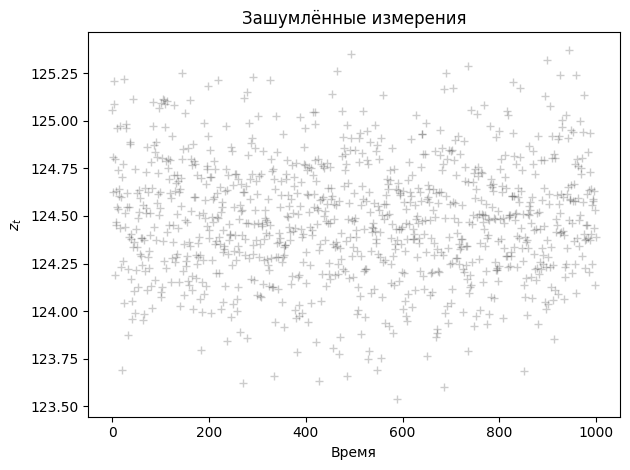

In [ ]:
mu = 124.5 # Фактическое положение
R = 0.1    # Фактическое стандартное отклонение фактических измерений (R)

# Сгенерировать измерения
n_measurements = 1000 # Измените количество точек, чтобы увидеть, как изменится сходимость.
Z = np.random.normal(mu, np.sqrt(R), size=n_measurements)

plt.plot(Z,'k+',label='measurements $z_t$',alpha=0.2)
plt.title('Зашумлённые измерения')
plt.xlabel('Время')
plt.ylabel('$z_t$')
plt.tight_layout();

- Как обсуждалось ранее, поскольку фактическая ковариация шума измерений неизвестна, нам необходимо дать её оценку.

- Обычно это осуществимо, поскольку мы можем оценить $R$ на основе имеющихся измерени.

- Кроме того, нам необходимо оценить ковариацию шума процесса $Q$, что обычно слодть.

- Помните, что $Q$ представляет собой шум модели, используемой для описания фактического полоения.

- В нашем случае:

$$x_t = x_0 + w_t \;\; \text{with}\;\; w_t \sim \mathcal{N}(0,Q)$$

- В итоге, у нас есть два параметра шума: один для модели ($Q$) и один для измерения ($R$).
- Значения $Q$ и $R$ являются входными данными для алгоритма.
- Следовательно, поскольку мы обычно не знаем $Q$ и $R$, нам приходится делать обоснованные предположения.

- В этом примере нам известна фактическая дисперсия измерений (поскольку мы сами генерируем измерения).

- Мы можем увидеть влияние хорошей или плохой оценки этого параметр.

- Кроме того, нам известно фактическое положение нашего автомобиля, поэтому мы можем увидеть, как быстро фильтр Калмана сходится к истинному значеию.

- Наконец, нам нужно предположить начальные значения для начального положения автомобиля и дисперсии этой начальной оценки.

In [ ]:
# Оценки ковариаций
Q_est = 1e-4
R_est = 2e-2

- Создадим функцию, которая вычисляет предполагаемое положение и связанную с ним погрешность, используя фильтр Калмана.

In [ ]:
def kalman_1d(x, P, measurement, R_est, Q_est):

    # Прогноз
    x_pred = x
    P_pred = P + Q_est

    # Коррекция
    K = P_pred / (P_pred + R_est)
    x_est = x_pred + K * (measurement - x_pred)
    P_est = (1 - K) * P_pred

    return x_est, P_est

- Применим фильтр к одномерным статическим измерениям.

In [ ]:
# первоначальные предположения
x = 123 # Используйте целое число
P = 0.04 # ковариация ошибок P

KF_estimate=[] # Для хранения оценки местоположения в каждой точке времени
KF_error=[] # Для хранения оценки погрешности в каждой точке времени
for z in Z:
    x, P = kalman_1d(x, P, z, R_est, Q_est)
    KF_estimate.append(x)
    KF_error.append(P)

- Теперь построим график оценки значения $x_t$ поверх измерений $z_t$.
- Также построим график изменения оценки ковариации $P_t$ в процессе.

In [ ]:
def plot_1d_comparison(measurements_made, estimate, true_value, axis):
    axis.plot(measurements_made,'k+',label='измерения',alpha=0.3)
    axis.plot(estimate,'-',label='Оценка KF')
    if not isinstance(true_value, (list, tuple, np.ndarray)):
        # график для постоянного значения
        axis.axhline(true_value,color='r',label='истинные значения', alpha=0.5)
    else:
        axis.plot(true_value,color='r',label='истинное значение', alpha=0.5)
    axis.legend(loc = 'lower right')
    axis.set_title('Расчетное положение в зависимости от времени')
    axis.set_xlabel('Время')
    axis.set_ylabel('$x_t$')

def plot_1d_error(estimated_error, lower_limit, upper_limit, axis):
    # lower_limit и upper_limit — это нижний и верхний пределы вертикальной оси
    axis.plot(estimated_error, label='КФ оценка $P$')
    axis.legend(loc = 'upper right')
    axis.set_title('Оценка погрешности в зависимости от времени')
    axis.set_xlabel('Время')
    axis.set_ylabel('$P_t$')
    plt.setp(axis,'ylim',[lower_limit, upper_limit])

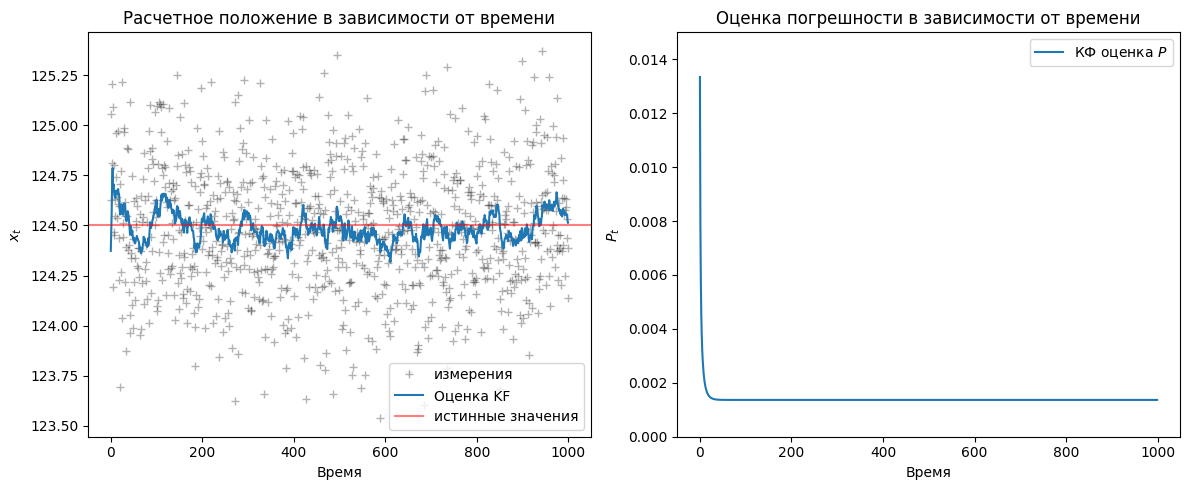

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(12, 5))
plot_1d_comparison(Z, KF_estimate, mu, axes[0])
plot_1d_error(KF_error, 0, 0.015, axes[1])
plt.tight_layout();

- Мы видим, что при выбранных нами параметрах фильтр быстро сходится к истинному значению, и шум отфильтровывается.

**Вопрос:** Насколько сильно оценка KF колеблется вокруг истинного значения?

**Ответ:** Колебания вокруг истинного значения приблизительно равны стандартному отклонению оценки, которое составляет $\sqrt{P_t}$.

### Пример 2: Динамические одномерные данные

- Рассмотрим теперь автомобиль, движущийся с начальной скоростью $v_0$ и постоянным ускорением $a$.
- Положение изменяется со временем согласно следующей формуле:

$$x_{t} = x_{t-1} + \delta t \cdot v_0 + \delta t^2 \cdot a + w_t$$

- где $w_t \sim \mathcal{N}(0, Q)$ представляет собой шум модели.

- Теперь предположим, что у нас есть измерения только положения, но нет скорости:
$$z_t = x_t$$
- На практике для имитации наших измерений мы используем следующее распределение:
$$z_t \sim \mathcal{N}(x_t, R)$$
- где $R$ представляет собой дисперсию ошибки измерений.

- Теперь давайте изменим наш статический алгоритм, чтобы учесть это движение.
- Мы строим реальную траекторию.
- Мы моделируем измерения положений.
- Затем мы применим фильтр Калмана и сравним оценку положения, полученную с помощью фильтра Калмана, как с фактическим положением $x_t = x_0 + v_0 \cdot t$, так и с измеренными положениями $z_t$.

In [ ]:
# Зададим параметры
v0 = 0.3
a = 5e-3
x0 = 0.0
R = 8.0
delta_t = 0.1

# генерируем истинные позиции
n_measurements = 1000
Xt = np.zeros(n_measurements)
for t in range(0, n_measurements):
    Xt[t]= x0 + v0*t*delta_t + a*t**2*delta_t**2

# генерируем зашумлённые измерения
Zx = np.zeros(n_measurements)
for t in range(0, n_measurements):
    Zx[t]= Xt[t] + np.random.normal(0, np.sqrt(R))

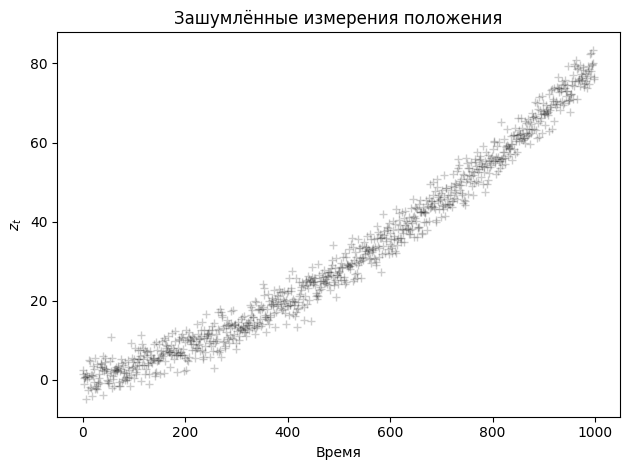

In [ ]:
plt.plot(Zx,'k+',label='measurements $z_t$', alpha=0.2)
plt.title('Зашумлённые измерения положения')
plt.xlabel('Время')
plt.ylabel('$z_t$')
plt.tight_layout();

In [ ]:
# Первоначальные предположения и оценки
x = 0
P = 0.5
Q_est = 4
R_est = 4
KF_estimate = []  # оценка положения на каждом шаге по времени.
KF_error = []     # сюда погрешность

# Фильтр Калмана
for z in Zx:
    x, P = kalman_1d(x, P, z, R_est, Q_est)
    KF_estimate.append(x)
    KF_error.append(P)

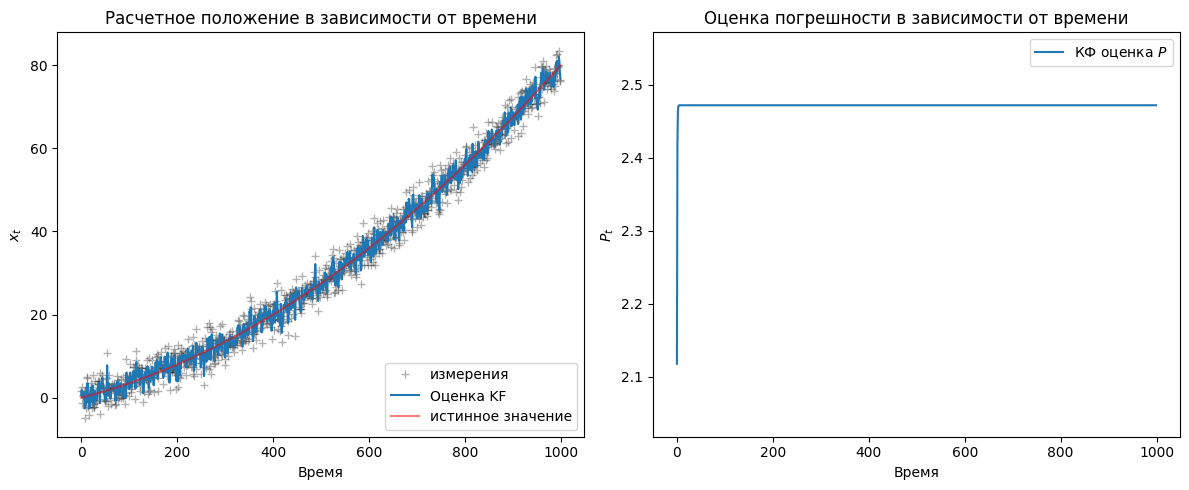

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(12, 5))
plot_1d_comparison(Zx, KF_estimate, Xt, axes[0])
plot_1d_error(KF_error, min(KF_error)-0.1, max(KF_error)+0.1, axes[1])
plt.tight_layout();

- Измерения не близки к истинному значению, поскольку дисперсия ошибки измерений $R$ велика по сравнению со скоростью.
- Оценка КФ отслеживает измерения, поэтому она колеблется вокруг истинного значения.

<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">&#9998 Note</b>
</p>

- В динамических моделях больше параметров для настройки, поэтому достижение сходимости может быть более сложной задачей.

- Если бы у нас был способ измерить скорость, мы могли бы использовать и эту информацию.
- Тем не менее, фильтр Калмана может работать с неполными наблюдениями, что является одним из его главных преимуществ.


### Пример 3: Динамические двумерные данные

- Теперь рассмотрим пример, более близкий к реальным задачам: оценка движения точки в двух измерениях, $x$ и $y$.
- Этот двумерный алгоритм используется в программах отслеживания движений мыши, а также для отслеживания объектов на видео.
- Как и прежде, мы будем использовать мгновенные измерения положения ($x, y$).
- Мы будем использовать фильтр Калмана, встроенный в OpenCV.

Наша система определяется следующими величинами:

- Вектор состояния $\boldsymbol{x} = \begin{bmatrix} x \\ y \\ \dot x \\ \dot y \end{bmatrix}$, представляющий двумерное положение и двумерную скорость.

- Вектор измерений $\boldsymbol{z} = \begin{bmatrix} z_x \\ z_y \end{bmatrix}$, представляющий измерения для двумерного положения.

- Матрица переходов$\mathbf{A} = \begin{bmatrix} 1 & 0 & \delta_t & 0 \\ 0 & 1 & 0 & \delta_t \\ 0 & 0 & 1 & 0 \\ 0 & 0 & 0 & 1 \end{bmatrix}$ (называется `transitionMatrix` в OpenCV).
  
- Матрица измерений $\mathbf{H} = \begin{bmatrix} 1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \end{bmatrix}$ (`measurementMatrix` в OpenCV).

- Ковариация шума модели $\mathbf{Q} = \begin{bmatrix}  q & 0 & 0 & 0 \\  0 & q & 0 & 0 \\ 0 & 0 & q & 0 \\ 0 & 0 & 0 & q  \end{bmatrix}$ ( `processNoiseCov` в OpenCV).

- Ковариация шума измерений $\mathbf{R} = \begin{bmatrix}  r & 0 \\ 0 & r  \end{bmatrix}$ (`measurementNoiseCov` в OpenCV).

Для простоты в этом примере мы используем диагональные ковариационные матрицы.

Конструктор имеет следующий синтаксис:

> `KalmanFilter(state_size, measurements_size, control_size)`

где
- `state_size` — размерность вектора состояния $\boldsymbol{x}$, которая в нашем случае равна 4.
- `measurements_size` — размерность вектора состояния $\boldsymbol{x}$, которая в нашем случае равна 2.
- `control_size`, которая равна 0, поскольку у нас нет необязательного управления $\boldsymbol{u}$ (не обсуждается в этом блокноте).

In [2]:
kalman = cv2.KalmanFilter(4,2,0) # 4 states, 2 measurements, 0 control vector

q = 1 # дисперсия в модели
r = 20 # дисперсия в измерении
dtime = 1 # размер временного шага

kalman.measurementMatrix = np.array([[1,0,0,0],
                                     [0,1,0,0]],np.float32) #  H
kalman.transitionMatrix = np.array([[1,0,dtime,0],
                                    [0,1,0,dtime],
                                    [0,0,1,0],
                                    [0,0,0,1]],np.float32) # A
kalman.processNoiseCov = np.array([[1,0,0,0],
                                   [0,1,0,0],
                                   [0,0,1,0],
                                   [0,0,0,1]],np.float32) * q # Q
kalman.measurementNoiseCov = np.array([[1,0],
                                       [0,1]],np.float32) * r # R

KF_estimate_xy = [] # Для хранения оценки местоположения в каждой точке времени

- Далее мы загрузим некоторые предварительно рассчитанные данные.

In [3]:
xy_motion = pd.read_csv('https://zenodo.org/records/10951538/files/kf_ts1.csv?download=1',
                        header = None).values.astype('float32')

- Здесь для простоты и воспроизводимости мы используем предварительно рассчитанные данные.
- Однако вы можете сгенерировать собственные измерения $(z_x, z_y)$, сначала щелкнув по сетке, а затем нажав «Сгенерировать образец».

In [4]:
from IPython.display import IFrame
IFrame('https://guoguibing.github.io/librec/datagen.html', width=900, height=800)

- Как всегда, перед анализом данных ознакомьтесь с ними.
- Также рекомендуется убедиться в корректности загрузки данных.

In [5]:
print(len(xy_motion))
print(xy_motion[0:10]) # первые 10 элементов, но можно просмотреть все 205 или построить график.

205
[[2.35 1.45]
 [3.55 1.8 ]
 [3.   2.9 ]
 [2.65 4.2 ]
 [2.95 5.15]
 [3.7  5.4 ]
 [4.8  5.55]
 [5.3  5.25]
 [5.7  5.25]
 [5.8  5.85]]


- Теперь мы готовы применить фильтр Калмана.
- В реализации фильтра Калмана в OpenCV отсутствуют параметры инициализации.
- И вектор состояния $\boldsymbol{x}$, и ковариационная матрица $\mathbf{P}$ всегда инициализируются нулем.

In [6]:
for i in xy_motion:
    pred = kalman.predict()  # прогнозирует новое состояние, используя модель
    kalman.correct((i))      # обновляет расчетное состояние с учетом результатов измерения
    KF_estimate_xy.append(((pred[0]),(pred[1]))) # сохранить предполагаемое местоположение

In [7]:
# Быстрая проверка: оценка имеет ту же длину, что и данные измерений.
print(len(KF_estimate_xy))

205


- Теперь построим график данных и оценки ФК.

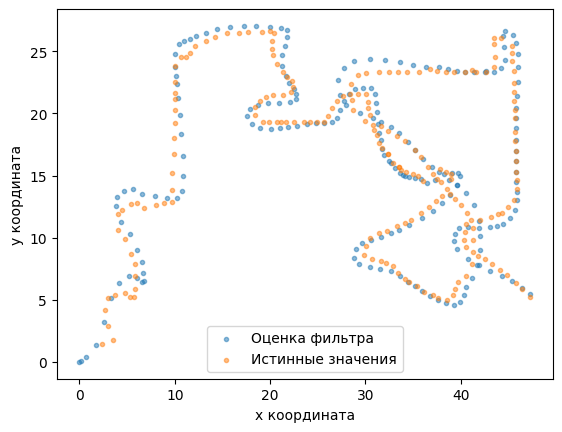

In [8]:
x_est, y_est = zip(*KF_estimate_xy)
x_true, y_true = zip(*xy_motion)
plt.scatter(x_est, y_est, marker= '.', label = 'Оценка фильтра', alpha = 0.5)
plt.scatter(x_true, y_true,marker= '.', label = 'Истинные значения', alpha = 0.5)
plt.legend(loc = 'lower center')
plt.xlabel('x координата')
plt.ylabel('y координата');

- В целом, хорошее согласие.
- Ещё раз, вам предлагается изменить параметры и посмотреть, что получится.

---